# Notebook 06: Comprehensive Evaluation & Comparison

Consolidate all model results and produce publication figures:
1. Full metrics table (all models × all cities)
2. Statistical significance tests
3. Climate transfer matrix
4. Error heatmaps (hour × month)
5. Prediction vs actual plots
6. Model ranking and summary

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sys.path.insert(0, os.path.abspath('.'))

from utils.city_config import CITY_METADATA, get_training_cities, get_test_cities, get_all_cities
from utils.metrics import (
    compute_all_metrics, r2_score, mae, rmse, skill_score,
    paired_t_test, bootstrap_confidence_interval
)
from utils.plotting import setup_plot_style, CITY_COLORS, COLORS

setup_plot_style()
os.makedirs('results/figures', exist_ok=True)

## 1. Load All Results

In [2]:
# Load baseline and Chronos results
baseline_df = pd.read_csv('results/baseline_results.csv') if os.path.exists('results/baseline_results.csv') else pd.DataFrame()
zs_df = pd.read_csv('results/chronos_zeroshot_results.csv') if os.path.exists('results/chronos_zeroshot_results.csv') else pd.DataFrame()
ft_df = pd.read_csv('results/chronos_finetuned_results.csv') if os.path.exists('results/chronos_finetuned_results.csv') else pd.DataFrame()

# Add model tags
if not zs_df.empty:
    zs_df['Model'] = 'Chronos-ZS'
if not ft_df.empty:
    ft_df['Model'] = 'Chronos-FT'

# Combine
all_results = pd.concat([baseline_df, zs_df, ft_df], ignore_index=True)
print(f"Total result rows: {len(all_results)}")
print(f"Models: {all_results['Model'].unique().tolist()}")
print(f"Cities: {all_results['City'].unique().tolist()}")

Total result rows: 72
Models: ['Persistence', 'LSTM', 'Transformer', 'Informer', 'Chronos-ZS', 'Chronos-FT']
Cities: ['Jaipur', 'Delhi', 'Guwahati', 'Ahmedabad', 'Chennai', 'Thiruvananthapuram', 'Nagpur', 'Hyderabad', 'Bangalore', 'Kolkata', 'Lucknow', 'Jodhpur']


## 2. Comprehensive Metrics Table

In [3]:
# Pivot: R² by Model × City
r2_pivot = all_results.pivot_table(index='City', columns='Model', values='R2', aggfunc='first')
print("R² Scores (All Models × All Cities):")
display(r2_pivot.round(4).style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1))

# MAE pivot
mae_pivot = all_results.pivot_table(index='City', columns='Model', values='MAE', aggfunc='first')
print("\nMAE (W/m²):")
display(mae_pivot.round(2).style.background_gradient(cmap='RdYlGn_r'))

R² Scores (All Models × All Cities):


Model,Chronos-FT,Chronos-ZS,Informer,LSTM,Persistence,Transformer
City,,,,,,
Ahmedabad,0.961600,0.965000,-0.822700,-0.561900,0.959300,-0.274200
Bangalore,0.949900,0.954100,-0.687800,-0.433300,0.951100,-0.228100
Chennai,0.923100,0.928300,-0.634600,-0.409100,0.916400,-0.194500
Delhi,0.930300,0.934000,-0.690600,-0.523800,0.918800,-0.199100
Guwahati,0.903600,0.910100,-0.357300,-0.255600,0.891700,-0.067600
Hyderabad,0.946100,0.950900,-0.671900,-0.429600,0.946400,-0.200100
Jaipur,0.942900,0.945900,-0.721500,-0.502200,0.932700,-0.234200
Jodhpur,0.959300,0.962800,-0.779000,-0.540300,0.956300,-0.270700
Kolkata,0.909200,0.909000,-0.449100,-0.313100,0.891200,-0.076300



MAE (W/m²):


Model,Chronos-FT,Chronos-ZS,Informer,LSTM,Persistence,Transformer
City,,,,,,
Ahmedabad,28.450000,24.140000,291.250000,268.970000,24.350000,223.950000
Bangalore,34.550000,30.920000,277.920000,254.590000,30.190000,219.740000
Chennai,39.280000,34.500000,263.150000,243.330000,35.960000,208.220000
Delhi,34.270000,30.770000,251.840000,240.030000,32.280000,196.400000
Guwahati,38.430000,34.240000,206.370000,199.140000,35.720000,172.660000
Hyderabad,33.860000,29.580000,265.780000,245.410000,29.610000,208.880000
Jaipur,33.620000,29.660000,274.220000,255.720000,31.580000,214.470000
Jodhpur,29.530000,25.300000,288.800000,267.820000,25.690000,225.000000
Kolkata,36.780000,34.440000,212.000000,202.510000,36.140000,172.060000


In [4]:
# Model averages (Train vs Test)
avg_results = all_results.groupby(['Model', 'Role']).agg(
    R2_mean=('R2', 'mean'),
    R2_std=('R2', 'std'),
    MAE_mean=('MAE', 'mean'),
    RMSE_mean=('RMSE', 'mean'),
).round(4)

display(avg_results)

# Save comprehensive results
all_results.to_csv('results/comprehensive_results.csv', index=False)
avg_results.to_csv('results/model_averages.csv')
print("Results saved.")

R2_mean  R2_std  MAE_mean  RMSE_mean
Model       Role                                       
Chronos-FT  Test    0.9396  0.0193   33.7928    67.6684
            Train   0.9318  0.0181   35.5695    72.8049
Chronos-ZS  Test    0.9430  0.0209   30.0749    65.4584
            Train   0.9358  0.0173   31.5257    70.6270
Informer    Test   -0.6400  0.1223  257.5955   359.6044
            Train  -0.6508  0.1439  260.8760   363.4308
LSTM        Test   -0.4347  0.0813  240.5694   336.1747
            Train  -0.4489  0.1006  244.0499   340.3814
Persistence Test    0.9345  0.0265   30.6256    69.9575
            Train   0.9228  0.0210   32.8948    77.3775
Transformer Test   -0.1886  0.0733  203.5740   306.1015
            Train  -0.1984  0.0659  205.7227   309.6426

Results saved.


## 3. Publication Figures

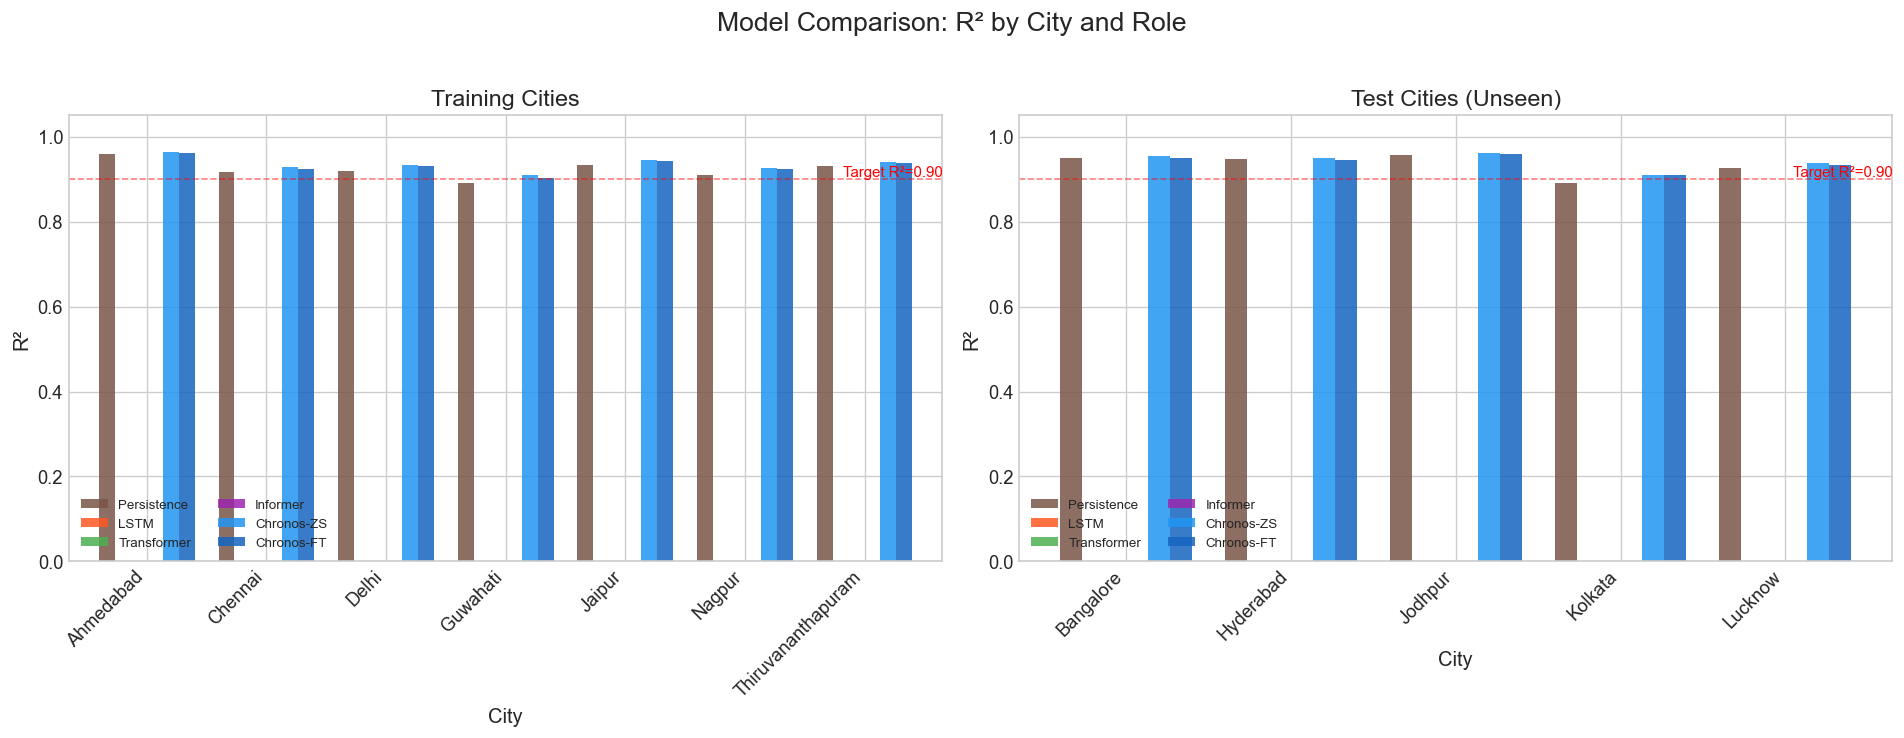

In [5]:
# Figure: Bar chart — R² comparison across all models
models_order = ['Persistence', 'LSTM', 'Transformer', 'Informer', 'Chronos-ZS', 'Chronos-FT']
models_present = [m for m in models_order if m in all_results['Model'].values]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, role, title in [(axes[0], 'Train', 'Training Cities'), (axes[1], 'Test', 'Test Cities (Unseen)')]:
    subset = all_results[all_results['Role'] == role]
    if subset.empty:
        continue
    
    pivot = subset.pivot_table(index='City', columns='Model', values='R2')
    pivot = pivot[[m for m in models_present if m in pivot.columns]]
    
    pivot.plot(kind='bar', ax=ax, width=0.8, alpha=0.85,
               color=[COLORS.get(m.lower().replace('-', '_'), '#333') for m in pivot.columns])
    ax.set_ylabel('R²')
    ax.set_title(title, fontsize=14)
    ax.axhline(0.90, color='red', linestyle='--', alpha=0.5, linewidth=1)
    ax.text(ax.get_xlim()[1], 0.90, 'Target R²=0.90', va='bottom', ha='right', color='red', fontsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    ax.legend(fontsize=8, ncol=2)
    ax.set_ylim(0, 1.05)

plt.suptitle('Model Comparison: R² by City and Role', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('results/figures/06_r2_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

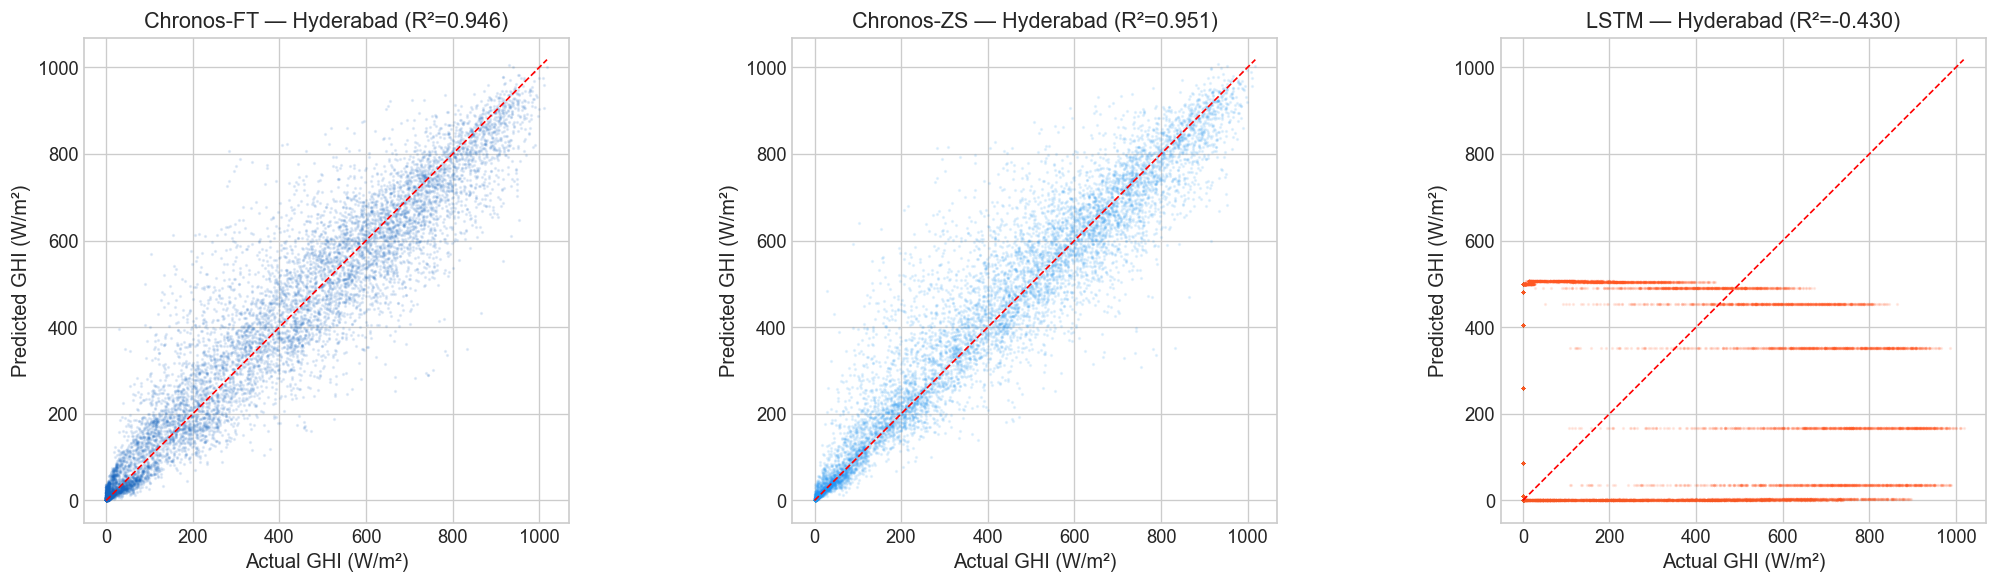

In [6]:
# Figure: Scatter plot — Prediction vs Actual (best model, sample city)
sample_city = get_test_cities()[0]  # First unseen test city

# Load predictions
pred_files = {
    'Chronos-FT': f'results/pred_chronos_finetuned_{sample_city}.npy',
    'Chronos-ZS': f'results/pred_chronos_zeroshot_{sample_city}.npy',
    'LSTM': f'results/pred_lstm_{sample_city}.npy',
}

# Load test targets
tgt_path = f'data/processed/windows/{sample_city}_test_targets.npy'
if os.path.exists(tgt_path):
    test_tgt = np.load(tgt_path)
    
    fig, axes = plt.subplots(1, len(pred_files), figsize=(6*len(pred_files), 5))
    if len(pred_files) == 1:
        axes = [axes]
    
    for ax, (model_name, path) in zip(axes, pred_files.items()):
        if not os.path.exists(path):
            continue
        pred = np.load(path)
        
        y_true = test_tgt.flatten()
        y_pred = pred.flatten()[:len(y_true)]
        
        ax.scatter(y_true, y_pred, alpha=0.1, s=1, color=COLORS.get(model_name.lower().replace('-', '_'), '#333'))
        ax.plot([0, y_true.max()], [0, y_true.max()], 'r--', linewidth=1)
        
        r2 = r2_score(y_true, y_pred)
        ax.set_xlabel('Actual GHI (W/m²)')
        ax.set_ylabel('Predicted GHI (W/m²)')
        ax.set_title(f'{model_name} — {sample_city.title()} (R²={r2:.3f})')
        ax.set_aspect('equal')
    
    plt.tight_layout()
    plt.savefig('results/figures/06_scatter_pred_vs_actual.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"Test targets not found for {sample_city}")

## 4. Statistical Significance Tests

In [7]:
# Paired t-test: Chronos-FT vs each baseline
stat_results = []

for city in get_all_cities():
    ft_path = f'results/pred_chronos_finetuned_{city}.npy'
    tgt_path = f'data/processed/windows/{city}_test_targets.npy'
    
    if not (os.path.exists(ft_path) and os.path.exists(tgt_path)):
        continue
    
    ft_pred = np.load(ft_path).flatten()
    tgt = np.load(tgt_path).flatten()
    n = min(len(ft_pred), len(tgt))
    ft_errors = np.abs(tgt[:n] - ft_pred[:n])
    
    for model_name in ['lstm', 'transformer', 'informer', 'chronos_zeroshot']:
        pred_path = f'results/pred_{model_name}_{city}.npy'
        if not os.path.exists(pred_path):
            continue
        baseline_pred = np.load(pred_path).flatten()
        n2 = min(n, len(baseline_pred))
        baseline_errors = np.abs(tgt[:n2] - baseline_pred[:n2])
        
        t_stat, p_val = paired_t_test(ft_errors[:n2], baseline_errors)
        stat_results.append({
            'City': city.title(),
            'Comparison': f'Chronos-FT vs {model_name}',
            't_statistic': t_stat,
            'p_value': p_val,
            'Significant (p<0.05)': p_val < 0.05,
        })

stat_df = pd.DataFrame(stat_results)
if not stat_df.empty:
    stat_df.to_csv('results/statistical_significance.csv', index=False)
    display(stat_df)
    print(f"\nSignificant improvements: {stat_df['Significant (p<0.05)'].sum()} / {len(stat_df)}")
else:
    print("No statistical test data available yet.")

,City,Comparison,t_statistic,p_value,Significant (p<0.05)
0,Jaipur,Chronos-FT vs lstm,-126.526632,0.0,True
1,Jaipur,Chronos-FT vs transformer,-108.987853,0.0,True
2,Jaipur,Chronos-FT vs informer,-128.055035,0.0,True
3,Jaipur,Chronos-FT vs chronos_zeroshot,23.431229,1.0,False
4,Delhi,Chronos-FT vs lstm,-122.353882,0.0,True
5,Delhi,Chronos-FT vs transformer,-104.765711,0.0,True
6,Delhi,Chronos-FT vs informer,-122.886270,0.0,True
7,Delhi,Chronos-FT vs chronos_zeroshot,22.024498,1.0,False
8,Guwahati,Chronos-FT vs lstm,-111.667000,0.0,True
9,Guwahati,Chronos-FT vs transformer,-99.245874,0.0,True



Significant improvements: 36 / 48


## 5. Error Analysis: Hour × Month Heatmap

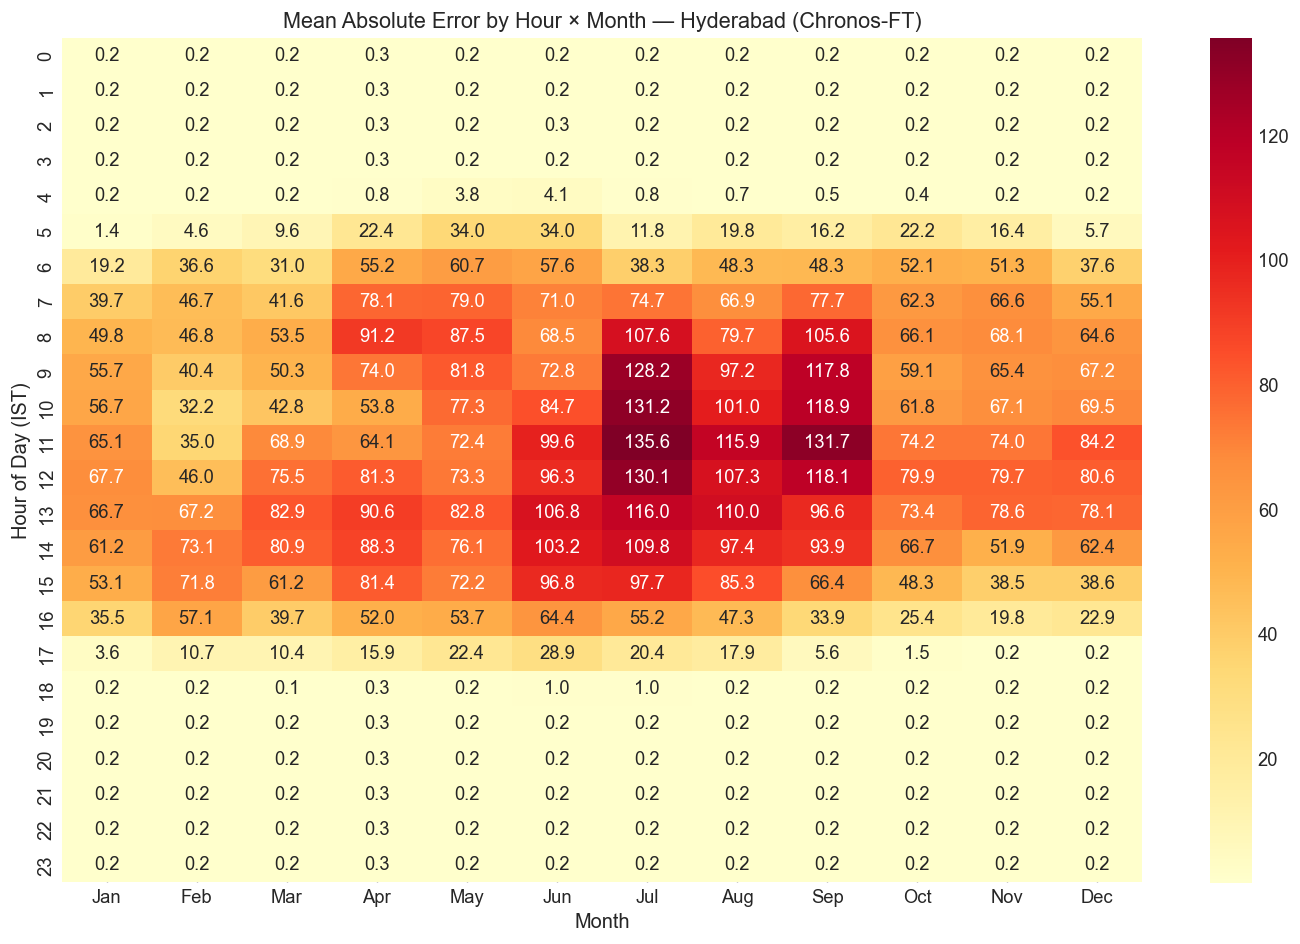

In [8]:
# Error heatmap for the best model on a sample city
sample_city = get_test_cities()[0]
pq_path = f'data/processed/parquet/{sample_city}_processed.parquet'
ft_path = f'results/pred_chronos_finetuned_{sample_city}.npy'
tgt_path = f'data/processed/windows/{sample_city}_test_targets.npy'

if all(os.path.exists(p) for p in [pq_path, ft_path, tgt_path]):
    pred = np.load(ft_path)
    tgt = np.load(tgt_path)
    
    # Load timestamps from processed data
    df_proc = pd.read_parquet(pq_path)
    from utils.city_config import VAL_END
    df_test = df_proc[df_proc['timestamp'] > pd.Timestamp(VAL_END)].reset_index(drop=True)
    
    # For each prediction window, compute error
    errors_data = []
    for i in range(min(len(pred), 500)):  # Sample for speed
        for h in range(24):
            err = abs(tgt[i, h] - pred[i, h])
            # Approximate timestamp
            ts_idx = i * 24 + 72 + h  # context + offset
            if ts_idx < len(df_test):
                ts = df_test['timestamp'].iloc[ts_idx]
                errors_data.append({'hour': ts.hour, 'month': ts.month, 'error': err})
    
    err_df = pd.DataFrame(errors_data)
    pivot = err_df.pivot_table(index='hour', columns='month', values='error', aggfunc='mean')
    
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
                xticklabels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
    ax.set_xlabel('Month')
    ax.set_ylabel('Hour of Day (IST)')
    ax.set_title(f'Mean Absolute Error by Hour × Month — {sample_city.title()} (Chronos-FT)')
    plt.tight_layout()
    plt.savefig('results/figures/06_error_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Required files not found for error heatmap.")

## 6. Climate Transfer Matrix

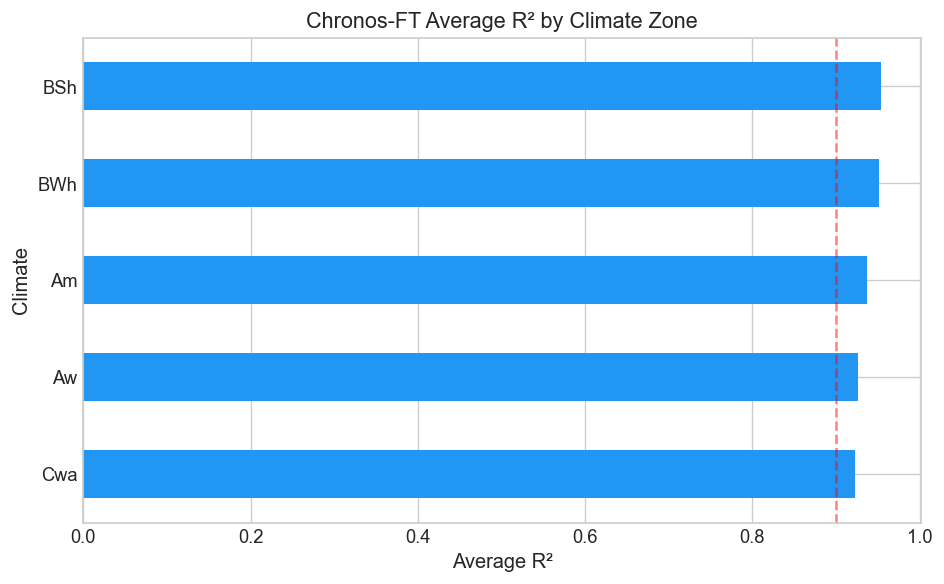

In [9]:
# R² by climate zone pairing (train zone → test zone)
if 'Climate' in all_results.columns:
    ft_only = all_results[all_results['Model'] == 'Chronos-FT']
    if not ft_only.empty:
        climate_r2 = ft_only.groupby('Climate')['R2'].mean()
        
        fig, ax = plt.subplots(figsize=(8, 5))
        climate_r2.sort_values(ascending=True).plot(kind='barh', ax=ax, color='#2196F3')
        ax.set_xlabel('Average R²')
        ax.set_title('Chronos-FT Average R² by Climate Zone')
        ax.axvline(0.90, color='red', linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.savefig('results/figures/06_climate_transfer.png', dpi=150, bbox_inches='tight')
        plt.show()
else:
    print("Climate column not in results.")

## 7. Final Summary

In [10]:
# Final model ranking
print("="*70)
print(" FINAL MODEL RANKING (by average R² on TEST cities)")
print("="*70)

test_results = all_results[all_results['Role'] == 'Test']
if not test_results.empty:
    ranking = test_results.groupby('Model').agg(
        R2_mean=('R2', 'mean'),
        R2_min=('R2', 'min'),
        R2_max=('R2', 'max'),
        MAE_mean=('MAE', 'mean'),
    ).sort_values('R2_mean', ascending=False)
    
    for i, (model, row) in enumerate(ranking.iterrows()):
        medal = ['🥇', '🥈', '🥉'][i] if i < 3 else '  '
        target = '✅' if row['R2_mean'] >= 0.90 else '❌'
        print(f"  {medal} {model:15s} | R²={row['R2_mean']:.4f} (min={row['R2_min']:.4f}, max={row['R2_max']:.4f}) | MAE={row['MAE_mean']:.2f} | Target {target}")

    print(f"\nTarget R² > 0.90 achieved: {(ranking['R2_mean'] >= 0.90).sum()} / {len(ranking)} models")
else:
    print("No test results available yet. Run notebooks 04 and 05 first.")

 FINAL MODEL RANKING (by average R² on TEST cities)
  🥇 Chronos-ZS      | R²=0.9430 (min=0.9090, max=0.9628) | MAE=30.07 | Target ✅
  🥈 Chronos-FT      | R²=0.9396 (min=0.9092, max=0.9593) | MAE=33.79 | Target ✅
  🥉 Persistence     | R²=0.9345 (min=0.8912, max=0.9563) | MAE=30.63 | Target ✅
     Transformer     | R²=-0.1886 (min=-0.2707, max=-0.0763) | MAE=203.57 | Target ❌
     LSTM            | R²=-0.4347 (min=-0.5403, max=-0.3131) | MAE=240.57 | Target ❌
     Informer        | R²=-0.6400 (min=-0.7790, max=-0.4491) | MAE=257.60 | Target ❌

Target R² > 0.90 achieved: 3 / 6 models


## Summary

**All results consolidated in:**
- `results/comprehensive_results.csv` — Full metrics table
- `results/model_averages.csv` — Aggregated by model and role
- `results/statistical_significance.csv` — Paired t-tests

**Publication figures in:** `results/figures/`

**Next:** Notebook 07 — Unseen City Validation & Variable-Horizon Testing